# Attention-based Neurosymbolic Differentiable Rule Extractor (ANDRE)

**Creator**: Iman Sharifi

## Predicate Selection Heuristic

In [10]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, data_type='boolean', entropy_threshold=1.5):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            # Find predicate value of a given neuron
            pred_value = pred_values[i]
            body_pred = body_preds[i]

            # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

            max_index = np.argmax(new_weights)
            if max_index == 0:
                interpretations.append(f'{body_pred}')
                continue
            elif max_index == 1:
                interpretations.append(f'not({body_pred})')
                continue
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'{body_preds[i]}')
            elif max_index == 1:
                interpretations.append(f'not({body_preds[i]})')
            else:
                interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, data_type='boolean', entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        data_type (str): The type of data, either 'boolean' or 'fuzzy'.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    if data_type == 'fuzzy':
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            pred_value = pred_values[i]
            new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
            max_index = np.argmax(new_weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')
    else:
        # For boolean data type, we assume pred_values are binary (0 or 1)
        for i, weights in enumerate(Weights):
            weights_tensor = torch.tensor(weights, dtype=torch.float32)
            entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
            # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

            if entropy > entropy_threshold:
                interpretations.append('1')
                continue

            max_index = np.argmax(weights)

            if max_index == 0:
                interpretations.append(f'b{i+1}')
            elif max_index == 1:
                interpretations.append(f'not(b{i+1})')
            else:
                interpretations.append('1')

    return interpretations

## Accuracy Metric

In [11]:
def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc


In [12]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

# Network Architecture

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0  # Example value for lambda
GAMMA = 0.5  # Example value for gamma, used in the attention mechanism

# Define CustomNeuron and ANDRE
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(0.2*self.raw_weights, dim=0)
        # self.weights = torch.sigmoid(self.raw_weights)  # Use sigmoid to ensure weights are in [0, 1]
        # self.weights = self.weights / self.weights.sum()  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

# Define ANDRE
class ANDRE(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(ANDRE, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - GAMMA))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - GAMMA))  # Apply sigmoid to the sum

        return activated_output

## Dataset Generation

Desired Rule:

$h(X_3) \leftarrow h_1(X_3) \vee h_2(X_3)$, where $h_1(X_3) \leftarrow b_1(X_1,X_2) \wedge \neg b_3(X_2,X_3)$, and $h_2(X_3) \leftarrow \neg b_2(X_1) \wedge b_4(X_1,X_3)$.

In [20]:
# Dataset
torch.manual_seed(42)
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
y_train = (((1 - X_train[:, 0]) > 0.5) & (X_train[:, 2] > 0.5) | ((X_train[:, 1]) > 0.5) & ((1-X_train[:, 3]) > 0.5)).float()


## Main Loop

V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/5 Final Loss: 0.0932
Restart 2/5 Final Loss: 0.0932
Restart 3/5 Final Loss: 0.1164
Restart 4/5 Final Loss: 0.0939
Restart 5/5 Final Loss: 0.0939


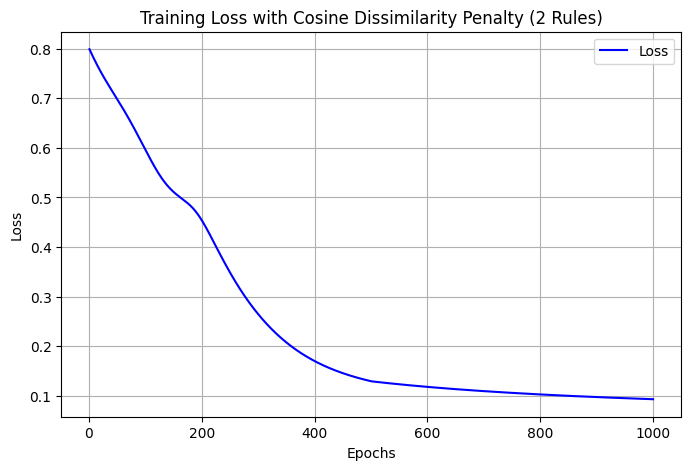

The most repeated rule is: 'h1 :- not(b1(X1, X2)) and b3(X2, X3).'
Accuracy over training data: 1.0.
The most repeated rule is: 'h2 :- b2(X1) and not(b4(X1, X3)).'
Accuracy over training data: 1.0.

Final Rule:
h :- not(b1(X1, X2)) and b3(X2, X3) OR b2(X1) and not(b4(X1, X3)).

Final M matrices:
M1: [1.7992682456970215, 1.7841347455978394, 1.3417994976043701]
M2: [2.2611000537872314, 0.9488065838813782, 1.3754808902740479]


In [ ]:
# Re-execution after kernel reset
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter

# Parameters
num_rules = 2
num_epochs = 1000
num_restarts = 5
similarity_weight = 0.1
entropy_weight = 0.01

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Define head variables
head_vars = [0, 2]  # Variables X1 and X3 are the head variables
# Define auxiliary variables
connected_vars = [1]  # Variable X2 is the auxiliary variable

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    andre_model = ANDRE(num_rules, num_neurons_per_rule, input_dim, V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(andre_model.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = andre_model(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = andre_model.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = andre_model.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = andre_model.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        # range_restricted_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))
        # range_restricted_loss is computed using this function: F(x) = sigmoid(-10 * (x - 0.5))
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(andre_model.entropies)

        total_loss = bce_loss - entropy_weight * entropy_term + 0.01 * range_restricted_loss + 0.01 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(andre_model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(andre_model.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = ANDRE(num_rules, num_neurons_per_rule, input_dim, V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")